# Preprocesamiento · del CSV a las fichas de entrenamiento

**Caso de uso III · Aprendizaje automático**

Este notebook convierte los datos descargados en las **fichas** con las que se entrenarán las tres redes (RNN, LSTM y GRU), aplicando las decisiones tomadas en el EDA (ver `docs/diario_de_ruta.md`).

```
CSV original ─► limpieza ─► entradas y objetivos ─► recorte y escalado (solo con train)
             ─► fichas de 10 a 252 días ─► partición E y walk-forward ─► comprobaciones
```

El código está en `src/oil_price/`, para que la aplicación prepare los datos exactamente igual:

| Módulo | Contenido |
|---|---|
| `config.py` | Todos los parámetros: fechas, variables, horizontes, ventanas, recortes, partición |
| `datos.py` | Carga y limpieza |
| `preprocesado.py` | Entradas, objetivos, recorte y escalado, fichas y particiones |
| `validaciones.py` | Comprobaciones automáticas (huecos, fugas de información) |
| `evaluacion.py` | Métricas (MSE, MAE, RMSE, dirección) y modelo ingenuo |

Las mismas comprobaciones se ejecutan como pruebas automáticas con `poetry run pytest`.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oil_price import config, datos, evaluacion, preprocesado as pp, validaciones as v
from oil_price.graficos import C, DIVERGENTE, EJE, TINTA_2, aplicar_estilo, eje_años

aplicar_estilo()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Carga y limpieza (D3, D5, D12, D13)

- El CSV original **no se modifica nunca** (D12).
- Los días reales de cotización del Brent se leen de `data/dias_brent.csv`, generado una sola vez desde FRED con `scripts/generar_dias_brent.py` (D13). Así el proceso funciona sin conexión y siempre da el mismo resultado.

In [2]:
crudo = datos.cargar_dataset()
dias_brent = datos.cargar_dias_brent()
limpio = datos.limpiar(crudo, dias_brent)

pd.DataFrame({
    "filas": [len(crudo), crudo.index.isin(dias_brent).sum(), len(limpio)],
    "columnas": [crudo.shape[1], crudo.shape[1], limpio.shape[1]],
}, index=["CSV original",
          "solo días reales del Brent (D3)",
          f"periodo {config.FECHA_INICIO:%d/%m/%Y}-{config.FECHA_CORTE:%d/%m/%Y} y variables elegidas (D5)"])

,filas,columnas
CSV original,7003,20
solo días reales del Brent (D3),6501,20
periodo 30/08/2000-03/11/2026 y variables elegidas (D5),6364,6


In [3]:
print("Precios no positivos en el CSV (se sustituyen por el valor anterior):")
print(datos.valores_no_positivos(crudo).to_string())
print(f"\nWTI del 20/04/2020 tras la limpieza: {limpio.loc['2020-04-20', 'wti']:.2f} $ (el del 17/04)")
v.comprobar_limpio(limpio, dias_brent)

Precios no positivos en el CSV (se sustituyen por el valor anterior):
Date           
2020-04-20  wti   -36.980

WTI del 20/04/2020 tras la limpieza: 18.31 $ (el del 17/04)


,conjunto,comprobación,ok
0,datos limpios,sin huecos,True
1,datos limpios,sin infinitos,True
2,datos limpios,todos los precios > 0,True
3,datos limpios,fechas en orden y sin duplicados,True
4,datos limpios,solo días reales del Brent,True


In [4]:
por_año = limpio.groupby(limpio.index.year).size()
print("Cotizaciones del Brent por año:")
print(por_año.loc[2001:2005].to_string())
print(f"Media 2006-2025: {por_año.loc[2006:2025].mean():.0f}")

Cotizaciones del Brent por año:
Date
2001    194
2002    194
2003    216
2004    230
2005    224
Media 2006-2025: 251


> ### Resultado de la limpieza
> - De 7.003 filas se pasa a **6.364 días reales del Brent** entre el 30/08/2000 y el 03/11/2026, con las 6 variables elegidas.
> - El único precio no positivo es el **WTI del 20/04/2020 (−36,98 $)**, que se sustituye por el del 17/04 (18,31 $).
> - Todas las comprobaciones de los datos limpios son correctas.
> - **Observación:** en 2001-2002 la EIA publicó solo ≈ 194 cotizaciones al año, frente a ≈ 251 desde 2006. En esos primeros años, 252 sesiones equivalen a algo más de un año natural. Solo afecta al inicio del train.

## 2. Variables de entrada (D4, D5)

Todas se calculan **solo con información disponible ese día** (una prueba automática lo verifica alterando el futuro y comprobando que el pasado no cambia).

In [5]:
base = pp.preparar_base(limpio)

DESCRIPCION = {
    "r_brent": "variación diaria del Brent",
    "r_wti": "variación diaria del WTI",
    "r_cobre": "variación diaria del cobre",
    "r_oro": "variación diaria del oro",
    "r_indice_dolar": "variación diaria del índice del dólar",
    "r_vix": "variación diaria del índice del miedo (VIX)",
    "log_vol_brent": "log de la volatilidad del Brent en 21 días (alarma de tormenta)",
    "nivel_brent": "log del precio frente a su media de 1 año (¿caro o barato?)",
}
e = base.entradas
print(f"Días con todas las entradas: {len(e):,} ({e.index[0]:%d/%m/%Y} → {e.index[-1]:%d/%m/%Y})")
pd.DataFrame({"qué mide": DESCRIPCION, "media": e.mean(), "desv. típica": e.std(),
              "mínimo": e.min(), "máximo": e.max()})

Días con todas las entradas: 6,113 (11/12/2001 → 03/11/2026)


,qué mide,media,desv. típica,mínimo,máximo
r_brent,variación diaria del Brent,0.000,0.027,-0.644,0.412
r_wti,variación diaria del WTI,0.000,0.029,-0.720,0.426
r_cobre,variación diaria del cobre,0.000,0.018,-0.252,0.124
r_oro,variación diaria del oro,0.000,0.012,-0.114,0.086
r_indice_dolar,variación diaria del índice del dólar,-0.000,0.005,-0.027,0.025
r_vix,variación diaria del índice del miedo (VIX),-0.000,0.073,-0.442,0.768
log_vol_brent,log de la volatilidad del Brent en 21 días (al...,-1.161,0.447,-2.472,1.234
nivel_brent,log del precio frente a su media de 1 año (¿ca...,0.015,0.230,-1.854,0.666


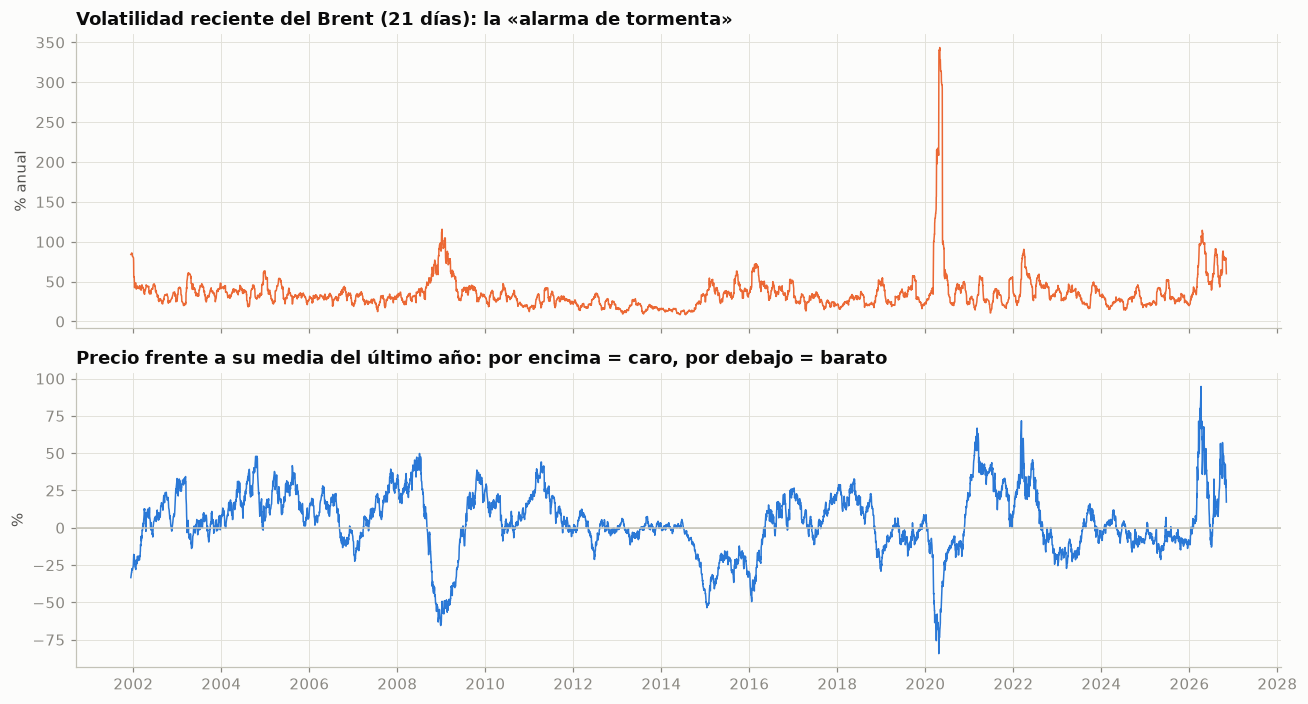

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(e.index, np.exp(e["log_vol_brent"]) * 100, color=C["naranja"], lw=1)
axes[0].set_ylabel("% anual")
axes[0].set_title("Volatilidad reciente del Brent (21 días): la «alarma de tormenta»")
axes[1].plot(e.index, np.expm1(e["nivel_brent"]) * 100, color=C["azul"], lw=1)
axes[1].axhline(0, color=EJE, lw=1)
axes[1].set_ylabel("%")
axes[1].set_title("Precio frente a su media del último año: por encima = caro, por debajo = barato")
eje_años(axes[1])
plt.tight_layout()
plt.show()

> ### Resultado de las entradas
> - 8 entradas por día: 6 variaciones diarias + 2 indicadores del Brent (volatilidad reciente y nivel frente a su media anual).
> - El indicador de nivel necesita 252 cotizaciones previas, así que **las entradas empiezan el 11/12/2001**: los primeros 15 meses solo sirven para calentar. Se usa el mismo inicio con y sin el indicador de nivel, para que las dos variantes sean comparables.
> - La volatilidad marca claramente las tormentas (2008, 2020 con un 340 %, 2022, 2026). El nivel muestra cuándo el precio está muy por encima o por debajo de lo normal: −85 % en 2020, +95 % en 2026.

## 3. Objetivos: la respuesta de cada ficha (D4)

Para cada día $t$ y horizonte $h$, el objetivo es la variación logarítmica del Brent: $y = \ln(P_{t+h} / P_t)$. El precio previsto se recupera como $P_t \cdot e^{\hat y}$. Ejemplo:

In [7]:
t = base.objetivos.loc["2021-06-01":].index[0]
ejemplo = {}
for nombre, h in config.HORIZONTES.items():
    fecha_obj = base.fechas_objetivo.loc[t, nombre]
    y = base.objetivos.loc[t, nombre]
    ejemplo[f"{nombre} ({h} sesiones)"] = {
        "hoy (t)": t.date(), "precio hoy ($)": limpio.loc[t, "brent"],
        "fecha objetivo (t+h)": fecha_obj.date(), "precio entonces ($)": limpio.loc[fecha_obj, "brent"],
        "objetivo y": round(y, 4), "variación (%)": round(np.expm1(y) * 100, 1)}
pd.DataFrame(ejemplo).T

,hoy (t),precio hoy ($),fecha objetivo (t+h),precio entonces ($),objetivo y,variación (%)
corto (5 sesiones),2021-06-01,70.030,2021-06-08,71.390,0.019,1.900
medio (63 sesiones),2021-06-01,70.030,2021-08-27,72.260,0.031,3.200
largo (252 sesiones),2021-06-01,70.030,2022-05-27,121.190,0.548,73.100


## 4. Recorte y escalado (D9), ajustados solo con train

El recorte limita las **variaciones diarias** a los percentiles calculados **con el train** (2000-2017); el escalado deja cada entrada con media 0 y desviación 1 en el train. El estudio (D9) compara tres opciones: sin recorte, 0,5-99,5 % y 1-99 %.

Los indicadores de volatilidad y nivel **no se recortan**: el gráfico de abajo muestra por qué.

In [8]:
fin_train = config.PARTICION["fin_train"]
entradas_train = base.entradas.loc[:fin_train]
entradas_despues = base.entradas.loc[base.entradas.index > fin_train]   # validación + test

def porcentaje_recortado(prep, entradas):
    columnas = prep.inferior_.index
    return ((entradas[columnas] < prep.inferior_) | (entradas[columnas] > prep.superior_)).mean() * 100

p1 = pp.Preparador((1.0, 99.0)).ajustar(entradas_train)
p05 = pp.Preparador((0.5, 99.5)).ajustar(entradas_train)
pd.DataFrame({
    "límite inferior (p1)": p1.inferior_, "límite superior (p99)": p1.superior_,
    "% recortado train (1-99)": porcentaje_recortado(p1, entradas_train),
    "% recortado 2018-hoy (1-99)": porcentaje_recortado(p1, entradas_despues),
    "% recortado 2018-hoy (0,5-99,5)": porcentaje_recortado(p05, entradas_despues),
})

,límite inferior (p1),límite superior (p99),% recortado train (1-99),% recortado 2018-hoy (1-99),"% recortado 2018-hoy (0,5-99,5)"
r_brent,-0.055,0.060,2.014,4.955,2.589
r_wti,-0.065,0.065,2.014,3.616,2.098
r_cobre,-0.054,0.050,2.014,0.536,0.268
r_oro,-0.032,0.029,2.014,2.009,0.759
r_indice_dolar,-0.013,0.013,2.014,0.938,0.536
r_vix,-0.165,0.212,2.014,3.080,1.518


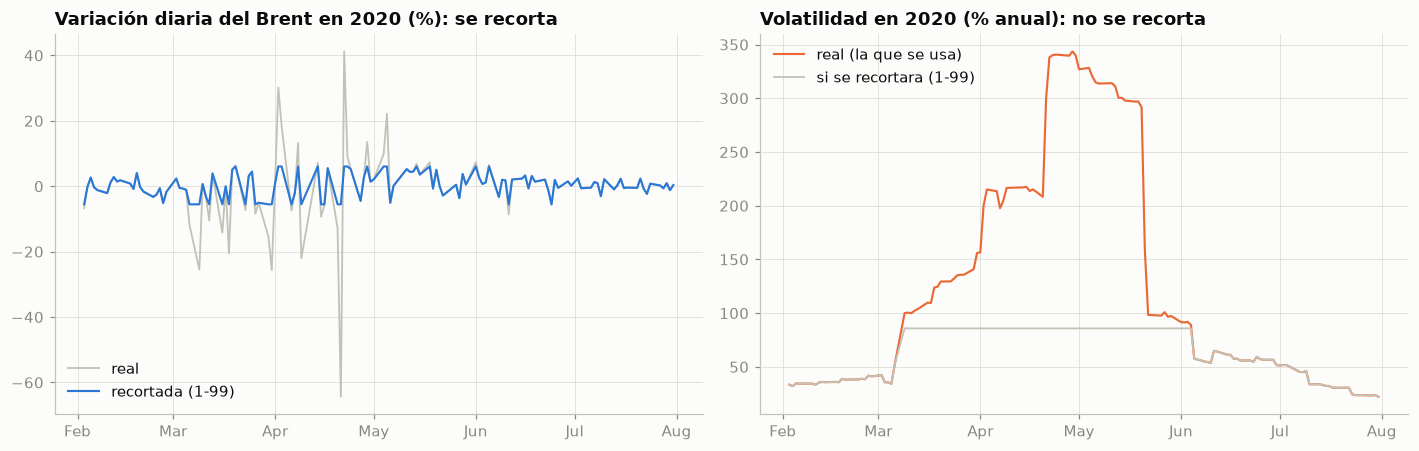

In [9]:
tramo = base.entradas.loc["2020-02-01":"2020-07-31"]
recortado = p1.recortar(tramo)
# Solo para ilustrar: qué pasaría si también se recortaran los indicadores
recortando_todo = pp.Preparador((1.0, 99.0), solo_variaciones=False).ajustar(entradas_train).recortar(tramo)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(tramo.index, tramo["r_brent"] * 100, color=EJE, lw=1.2, label="real")
axes[0].plot(tramo.index, recortado["r_brent"] * 100, color=C["azul"], lw=1.4, label="recortada (1-99)")
axes[0].set_title("Variación diaria del Brent en 2020 (%): se recorta")
axes[1].plot(tramo.index, np.exp(tramo["log_vol_brent"]) * 100, color=C["naranja"], lw=1.4,
             label="real (la que se usa)")
axes[1].plot(tramo.index, np.exp(recortando_todo["log_vol_brent"]) * 100, color=EJE, lw=1.2,
             label="si se recortara (1-99)")
axes[1].set_title("Volatilidad en 2020 (% anual): no se recorta")
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[0] else "upper left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout()
plt.show()

In [10]:
escaladas = p1.transformar(base.entradas)
pd.DataFrame({"media train": escaladas.loc[:fin_train].mean(),
              "desv. train": escaladas.loc[:fin_train].std(),
              "media 2018-hoy": escaladas.loc[entradas_despues.index].mean(),
              "desv. 2018-hoy": escaladas.loc[entradas_despues.index].std()})

,media train,desv. train,media 2018-hoy,desv. 2018-hoy
r_brent,0.000,1.000,0.013,1.125
r_wti,-0.000,1.000,0.009,1.076
r_cobre,0.000,1.000,-0.005,0.848
r_oro,-0.000,1.000,0.010,0.935
r_indice_dolar,0.000,1.000,0.022,0.807
r_vix,-0.000,1.000,-0.004,1.107
log_vol_brent,-0.000,1.000,0.350,1.181
nivel_brent,0.000,1.000,0.013,1.054


> ### Resultado del recorte y el escalado
> - Con el recorte 1-99 % se recorta, por construcción, el 2 % de los datos de train. Después de 2018 se recorta más en las variables más agitadas: **5 % del Brent, 3,6 % del WTI y 3,1 % del VIX**. Con el recorte suave (0,5-99,5 %), aproximadamente la mitad.
> - **Cambio respecto a lo previsto (D9):** se recortan solo las variaciones diarias. Si se recortaran también los indicadores, la volatilidad de 2020 (hasta un 340 %) se quedaría fija en el 86 % durante tres meses: la red perdería justo la señal de «esto es peor que nunca». Los indicadores ya son suaves y van en logaritmo.
> - Tras escalar, el periodo 2018-hoy queda centrado en 0 con desviación ≈ 1. La excepción es la volatilidad, que es más alta que en el train (+0,35 desviaciones de media): 2018-2026 fue un periodo más agitado que 2000-2017.

## 5. Fichas (D6)

Cada ficha es una matriz de **ventana × variables** que acaba en el día de origen. Se generan las seis ventanas del estudio (10, 20, 40, 60, 120 y 252 días; D6).

In [11]:
final = pp.evaluacion_final()
tamaños = {}
for ventana in config.VENTANAS:
    train, test, _ = pp.construir_particion(base, ventana, (1.0, 99.0), **final)
    tamaños[f"{ventana} días"] = {
        "forma train (fichas, días, variables)": train.X.shape,
        "forma test": test.X.shape,
        "memoria train (MB)": round(train.X.nbytes / 1e6, 1),
        "primera ficha de train": train.fechas[0].date(),
    }
pd.DataFrame(tamaños).T

,"forma train (fichas, días, variables)",forma test,memoria train (MB),primera ficha de train
10 días,"(4881, 10, 8)","(1223, 10, 8)",1.600,2002-01-03
20 días,"(4871, 20, 8)","(1223, 20, 8)",3.100,2002-01-22
40 días,"(4851, 40, 8)","(1223, 40, 8)",6.200,2002-03-06
60 días,"(4831, 60, 8)","(1223, 60, 8)",9.300,2002-04-03
120 días,"(4771, 120, 8)","(1223, 120, 8)",18.300,2002-07-24
252 días,"(4639, 252, 8)","(1223, 252, 8)",37.400,2003-03-18


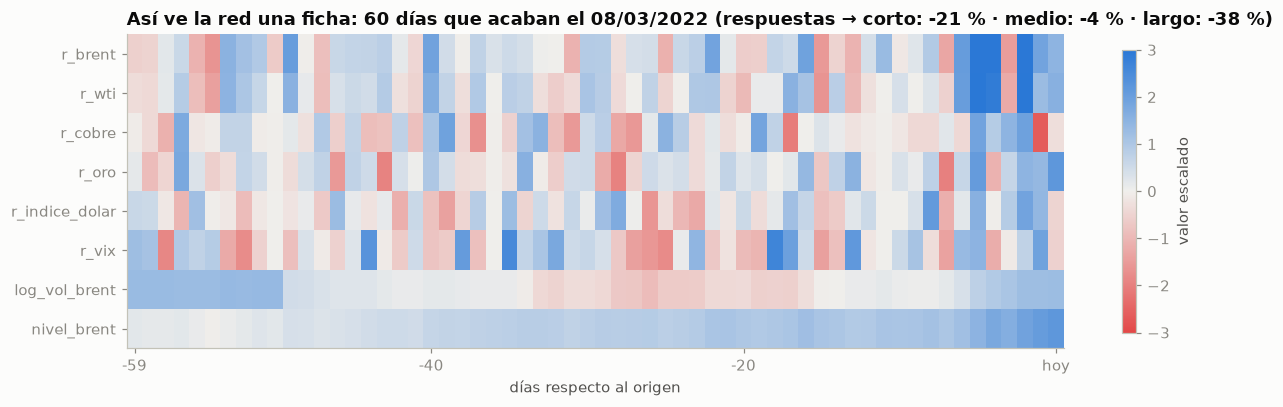

In [12]:
train, test, _ = pp.construir_particion(base, 60, (1.0, 99.0), **final)
i = int(np.flatnonzero(test.fechas >= "2022-03-08")[0])
ficha = test.X[i]

fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(ficha.T, aspect="auto", cmap=DIVERGENTE, vmin=-3, vmax=3)
ax.set_yticks(range(len(test.variables)), test.variables)
ax.set_xticks([0, 19, 39, 59], ["-59", "-40", "-20", "hoy"])
ax.set_xlabel("días respecto al origen")
ax.grid(False)
respuestas = " · ".join(f"{h}: {np.expm1(y) * 100:+.0f} %" for h, y in zip(test.horizontes, test.Y[i]))
ax.set_title(f"Así ve la red una ficha: 60 días que acaban el {test.fechas[i]:%d/%m/%Y} "
             f"(respuestas → {respuestas})")
fig.colorbar(im, ax=ax, label="valor escalado", shrink=0.9)
plt.tight_layout()
plt.show()

> ### Resultado de las fichas
> - Ventana de 60 días: **4.831 fichas de train** y **1.223 de test**, cada una de 60 × 8 valores. Con las demás ventanas, la cantidad cambia poco: de 4.881 (10 días) a 4.639 (252 días). Con la ventana de un año, la primera ficha de train llega en marzo de 2003, porque necesita un año de historia detrás.
> - Ocupan poca memoria (de 1,6 a 37 MB), así que no hace falta guardarlas en disco: se generan en menos de un segundo.
> - La ficha del 08/03/2022 (máximo tras la invasión de Ucrania) muestra cómo se ve un momento de tensión: subidas fuertes del Brent y el WTI los últimos días, volatilidad y nivel altos. Sus respuestas reales fueron −21 % a una semana, −4 % a tres meses y −38 % a un año.

## 6. Partición E y walk-forward (D7), con comprobaciones

Se construyen los 4 pliegues de validación y la evaluación final en test. En cada uno, el recorte y el escalado se **reajustan con su propio train**, y las respuestas que cruzarían al bloque siguiente se purgan.

In [13]:
resumen = {}
for p in pp.pliegues_walk_forward() + [pp.evaluacion_final()]:
    train, evaluado, _ = pp.construir_particion(base, 60, (1.0, 99.0), **p)
    resumen[p["nombre"]] = {"entrena hasta": p["fin_train"].date(), "fichas train": len(train),
                            **{f"evaluación: {k}": val for k, val in evaluado.resumen().items()}}
pd.DataFrame(resumen).T

,entrena hasta,fichas train,evaluación: fichas,evaluación: desde,evaluación: hasta,evaluación: objetivos corto,evaluación: objetivos medio,evaluación: objetivos largo
pliegue 1 (valida 2018),2017-12-31,3814,252,2018-01-02,2018-12-28,252,252,252
pliegue 2 (valida 2019),2018-12-31,4066,257,2019-01-02,2019-12-31,257,257,257
pliegue 3 (valida 2020),2019-12-31,4323,255,2020-01-02,2020-12-31,255,255,255
pliegue 4 (valida 2021),2020-12-31,4578,253,2021-01-04,2021-12-31,248,190,1
test,2021-12-31,4831,1223,2022-01-03,2026-11-03,1218,1160,971


In [14]:
# Todas las combinaciones del estudio: ventanas x recortes x 2 variantes de entradas x 5 particiones
comprobaciones = []
for con_nivel in (True, False):
    base_variante = pp.preparar_base(limpio, con_nivel=con_nivel)
    for ventana in config.VENTANAS:
        for recorte in config.RECORTES:
            for p in pp.pliegues_walk_forward() + [pp.evaluacion_final()]:
                train, evaluado, prep = pp.construir_particion(base_variante, ventana, recorte, **p)
                comprobaciones += [v.comprobar_conjunto(train), v.comprobar_conjunto(evaluado),
                                   v.comprobar_sin_fuga(train, evaluado, prep)]
todas = pd.concat(comprobaciones)
n_combinaciones = len(config.VENTANAS) * len(config.RECORTES) * 2 * 5
print(f"{len(todas):,} comprobaciones ejecutadas en {n_combinaciones} combinaciones: todas correctas = {todas['ok'].all()}")
todas.groupby("comprobación")["ok"].agg(["count", "all"]).rename(columns={"count": "veces", "all": "todas ok"})

2,700 comprobaciones ejecutadas en 180 combinaciones: todas correctas = True


,veces,todas ok
comprobación,,
cada objetivo es posterior a su ficha,360,True
entradas sin huecos ni infinitos,360,True
la ventana acaba en el origen,360,True
las fichas de train son anteriores a las de evaluación,180,True
ninguna respuesta de train cae en el periodo de evaluación,180,True
ningún objetivo pasa del límite del bloque,360,True
objetivo NaN ⇔ fecha de objetivo vacía,360,True
objetivos válidos finitos,360,True
recorte y escalado ajustados solo con train,180,True


**Una red por horizonte (D18).** Cada red se entrena solo con las fichas que tienen respuesta para su horizonte. A 252 sesiones se pierde el último año de cada bloque, que todavía no tiene respuesta.

In [15]:
train, test, _ = pp.construir_particion(base, 60, (1.0, 99.0), **pp.evaluacion_final())
pd.DataFrame({h: {"fichas train": len(pp.por_horizonte(train, h)), "fichas test": len(pp.por_horizonte(test, h))}
              for h in config.HORIZONTES}).T

,fichas train,fichas test
corto,4826,1218
medio,4768,1160
largo,4579,971


> ### Resultado de las particiones
> - 4 pliegues de validación de unas 250 fichas cada uno y un test de 1.223 fichas.
> - A 252 días, el pliegue de 2021 solo tiene 1 respuesta válida (las demás caerían en el test), así que **el largo plazo se valida en la práctica con 3 pliegues**, como ya se previó en el EDA.
> - **2.700 comprobaciones superadas** en las 180 combinaciones posibles (6 ventanas × 3 recortes × 2 variantes de entradas × 5 particiones): sin huecos, sin respuestas fuera de su bloque y con el recorte y el escalado ajustados siempre solo con el train.
> - Con una red por horizonte (D18), en el entrenamiento final hay 4.826 fichas para 5 sesiones, 4.768 para 63 y 4.579 para 252. En test, 1.218, 1.160 y 971.

## 7. El listón: modelo ingenuo sobre las mismas fichas

El modelo ingenuo («el precio futuro = el precio de hoy») se evalúa sobre **exactamente las mismas fichas** que usarán las redes. Estas cifras son las que cada red tendrá que mejorar. La ventana no cambia las fichas de evaluación, así que el listón es el mismo para todas las ventanas.

In [16]:
filas = {}
for p in pp.pliegues_walk_forward() + [pp.evaluacion_final()]:
    _, evaluado, _ = pp.construir_particion(base, 60, (1.0, 99.0), **p)
    filas[p["nombre"]] = evaluacion.metricas(evaluado)

def agrupar(tablas):
    """Une varios pliegues ponderando por número de muestras."""
    n = sum(t["muestras"] for t in tablas)
    mse = sum(t["MSE"] * t["muestras"] for t in tablas) / n
    mae = sum(t["MAE"] * t["muestras"] for t in tablas) / n
    return pd.DataFrame({"muestras": n, "MSE": mse, "MAE": mae, "RMSE": np.sqrt(mse)})

filas["validación (4 pliegues juntos)"] = agrupar([filas[p["nombre"]] for p in pp.pliegues_walk_forward()])
liston = pd.concat({k: t[["muestras", "MAE", "RMSE"]] for k, t in filas.items()}).unstack()
liston = liston.reindex(columns=list(config.HORIZONTES), level=1)
liston

muestras                     MAE                RMSE              
                                   corto     medio   largo corto  medio  largo corto  medio  largo
pliegue 1 (valida 2018)          252.000   252.000 252.000 2.455  9.040  9.048 2.954 11.560 11.068
pliegue 2 (valida 2019)          257.000   257.000 257.000 1.920  8.523 23.075 2.520 12.653 26.858
pliegue 3 (valida 2020)          255.000   255.000 255.000 2.873 15.787 30.265 4.199 20.009 32.784
pliegue 4 (valida 2021)          248.000   190.000   1.000 2.297  6.597 26.870 3.069  8.054 26.870
test                           1,218.000 1,160.000 971.000 3.987 11.944 16.502 5.738 17.437 22.527
validación (4 pliegues juntos) 1,012.000   954.000 765.000 2.386 10.217 20.856 3.246 14.084 25.336

> ### El listón
> | | Corto (5) | Medio (63) | Largo (252) |
> |---|---|---|---|
> | **Validación** (MAE ingenuo, 4 pliegues) | 2,39 $ | 10,22 $ | 20,86 $ |
> | **Test** (MAE ingenuo) | 3,99 $ | 11,94 $ | 16,50 $ |
>
> - Coinciden con el EDA, lo que confirma que las fichas reproducen exactamente los periodos analizados.
> - La dificultad cambia mucho entre años: a 252 días, el MAE va de 9 $ (2018) a 30 $ (2020). Por eso conviene mirar los pliegues por separado y no solo la media.

## 8. Conclusiones

| Paso | Qué se hace | Decisión |
|---|---|---|
| Limpieza | Días reales del Brent, 30/08/2000-03/11/2026, WTI negativo corregido | D3, D5, D12, D13 |
| Entradas | 6 variaciones diarias + volatilidad (21 días) + nivel frente a la media anual (se probará con y sin) | D4, D5 |
| Objetivos | Variación logarítmica del Brent a 5, 63 y 252 sesiones | D4 |
| Recorte y escalado | Solo las variaciones diarias se recortan (estudio: sin recorte / 0,5-99,5 / 1-99); escalado a media 0 y desviación 1; todo ajustado solo con train | D9 |
| Fichas | Ventanas de 10, 20, 40, 60, 120 y 252 días (estudio, una ventana por horizonte); fichas separadas por horizonte | D6, D18 |
| Particiones | Partición E, 4 pliegues walk-forward con purga + test | D7 |
| Comprobaciones | 2.700 comprobaciones superadas + pruebas automáticas (`poetry run pytest`) | D14 |

**Lo que queda listo para el modelado:** con una sola llamada (`pp.construir_particion(base, ventana, recorte, **pliegue)`) se obtienen las fichas de cualquier combinación del estudio, y `evaluacion.metricas()` da el listón del ingenuo sobre las mismas fichas.

**Siguiente paso:** instalar PyTorch y construir las tres redes (RNN, LSTM, GRU) con una misma definición donde solo cambia la celda.